**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación - CICESE  
M.C. Joan Manuel Raygoza Romero

# ICD - 19: Aprendizaje No Supervisado

Sesión 19 del curso. Diapositivas: [icd-19-aprendizaje-no-supervisado.pdf](https://github.com/husseinlopez/icd2026/blob/main/clases/icd-19-aprendizaje-no-supervisado.pdf)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/husseinlopez/icd2026/blob/main/icd-19-aprendizaje-no-supervisado.ipynb)

# Comparación de algoritmos de clustering

**K-means · DBSCAN · Gaussian Mixture Models (GMM) · Spectral Clustering**

En este notebook veremos cómo **cuatro algoritmos de aprendizaje no supervisado** agrupan los mismos datos. Utilizaremos tres conjuntos sintéticos de complejidad creciente:

1. **Grupos esféricos:** tres agrupaciones compactas y separadas.
2. **Grupos elípticos:** tres distribuciones gaussianas alargadas y con distintas orientaciones.
3. **Lunas entrelazadas:** dos grupos con formas no convexas.

El objetivo es **comparar visualmente** los resultados. Inspirado en la presentación *Aprendizaje no supervisado*, especialmente en las secciones sobre K-means, DBSCAN, GMM y Spectral Clustering.

## 1. ¿Qué considera cada algoritmo como un clúster?

| Algoritmo | Idea principal | Parámetros que probaremos |
|---|---|---|
| **K-means** | Observaciones cercanas a un centroide | `n_clusters` |
| **DBSCAN** | Regiones densas conectadas; puede identificar ruido | `eps`, `min_samples` |
| **GMM** | Datos generados por una mezcla de gaussianas; estima probabilidades de pertenencia | `n_components` |
| **Spectral Clustering** | Grupos muy conectados dentro de un grafo de similitud | `n_clusters`, `gamma` |

**Importante:** K-means, GMM y Spectral Clustering reciben el número de grupos `K`. DBSCAN **no** necesita `K`, pero es sensible a la escala de los datos y al valor de `eps`.

## 2. Importar las bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture

SEED = 42
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

## 3. Crear los tres conjuntos de datos

Todos tendrán **450 observaciones en dos dimensiones**. Aplicamos `StandardScaler` para que las variables tengan una escala comparable; cada algoritmo recibe exactamente los **mismos puntos** dentro de cada caso.

Los parámetros `eps` y `gamma` son ejemplos ajustados para visualizar el comportamiento de cada método. No representan valores universales.

In [ ]:
# Caso 1: grupos aproximadamente esféricos
X_esferas, _ = make_blobs(
    n_samples=450,
    centers=[(-3, -1), (2.5, 0.7), (-0.5, 3.5)],
    cluster_std=[0.50, 0.65, 0.55],
    random_state=SEED
)

# Caso 2: gaussianas alargadas y orientadas de manera diferente
rng = np.random.default_rng(SEED)
medias = [(-2, -0.2), (0, 0), (2, 0.2)]
covarianzas = [
    [[0.25, 1.00], [1.00, 5.00]],
    [[0.25, -0.90], [-0.90, 4.80]],
    [[0.20, 0.80], [0.80, 5.00]],
]
X_elipses = np.vstack([
    rng.multivariate_normal(media, cov, size=150)
    for media, cov in zip(medias, covarianzas)
])

# Caso 3: lunas entrelazadas (forma no convexa)
X_lunas, _ = make_moons(n_samples=450, noise=0.065, random_state=SEED)

# Parámetros editables de los cuatro algoritmos para cada conjunto
casos = {
    "Esferas": {"X": X_esferas, "k": 3, "eps": 0.26, "min_samples": 7, "gamma": 2},
    "Elipses": {"X": X_elipses, "k": 3, "eps": 0.19, "min_samples": 7, "gamma": 8},
    "Lunas":   {"X": X_lunas,   "k": 2, "eps": 0.23, "min_samples": 7, "gamma": 15},
}

for caso in casos.values():
    caso["X"] = StandardScaler().fit_transform(caso["X"])

print("Conjuntos preparados:", ", ".join(casos))

Conjuntos preparados: Esferas, Elipses, Lunas


### Visualización de los datos originales

En estos gráficos **todavía no se ha aplicado clustering** y no se utilizan las etiquetas empleadas internamente para generar los datos.

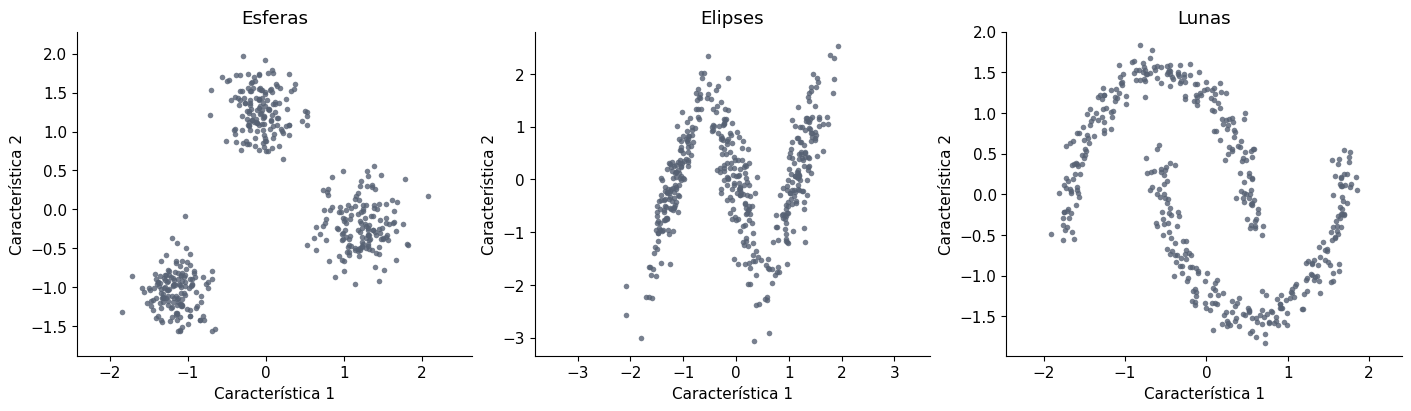

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, (nombre, caso) in zip(axes, casos.items()):
    X = caso["X"]
    ax.scatter(X[:, 0], X[:, 1], s=16, c="#566173", alpha=0.8, linewidths=0)
    ax.set(title=nombre, xlabel="Característica 1", ylabel="Característica 2")
    ax.set_aspect("equal", adjustable="datalim")
plt.show()

## 4. Ajustar los cuatro algoritmos

Usaremos `fit_predict(X)` para obtener la etiqueta de clúster asignada a cada punto. En **DBSCAN**, la etiqueta `-1` significa **ruido**, es decir, una observación no asignada a ningún clúster.

**Nota:** cada algoritmo numera los clústeres por su cuenta; por ejemplo, el clúster `0` de K-means no necesariamente equivale al clúster `0` de GMM.

In [ ]:
def ejecutar_algoritmos(X, k, eps, min_samples, gamma):
    algoritmos = {
        "K-means": KMeans(n_clusters=k, n_init=10, random_state=SEED),
        "DBSCAN": DBSCAN(eps=eps, min_samples=min_samples),
        "GMM": GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=SEED),
        "Spectral": SpectralClustering(
            n_clusters=k, affinity="rbf", gamma=gamma,
            assign_labels="kmeans", n_init=10, random_state=SEED
        ),
    }
    return {nombre: modelo.fit_predict(X) for nombre, modelo in algoritmos.items()}

resultados = {
    nombre: ejecutar_algoritmos(**caso)
    for nombre, caso in casos.items()
}

print("Se ajustaron cuatro modelos por cada conjunto de datos.")

Se ajustaron cuatro modelos por cada conjunto de datos.


## 5. Comparación visual: datos originales y resultados

Cada **fila** corresponde a un conjunto de datos y cada **columna** a un algoritmo. Los colores identifican los grupos predichos dentro de cada panel; los puntos **grises** en DBSCAN representan ruido.

Observa en particular cómo se comportan los métodos ante **formas alargadas** y **formas no convexas**.

In [ ]:
plt.get_cmap("tab20c").colors[::]

((0.19215686274509805, 0.5098039215686274, 0.7411764705882353),
 (0.4196078431372549, 0.6823529411764706, 0.8392156862745098),
 (0.6196078431372549, 0.792156862745098, 0.8823529411764706),
 (0.7764705882352941, 0.8588235294117647, 0.9372549019607843),
 (0.9019607843137255, 0.3333333333333333, 0.050980392156862744),
 (0.9921568627450981, 0.5529411764705883, 0.23529411764705882),
 (0.9921568627450981, 0.6823529411764706, 0.4196078431372549),
 (0.9921568627450981, 0.8156862745098039, 0.6352941176470588),
 (0.19215686274509805, 0.6392156862745098, 0.32941176470588235),
 (0.4549019607843137, 0.7686274509803922, 0.4627450980392157),
 (0.6313725490196078, 0.8509803921568627, 0.6078431372549019),
 (0.7803921568627451, 0.9137254901960784, 0.7529411764705882),
 (0.4588235294117647, 0.4196078431372549, 0.6941176470588235),
 (0.6196078431372549, 0.6039215686274509, 0.7843137254901961),
 (0.7372549019607844, 0.7411764705882353, 0.8627450980392157),
 (0.8549019607843137, 0.8549019607843137, 0.921568

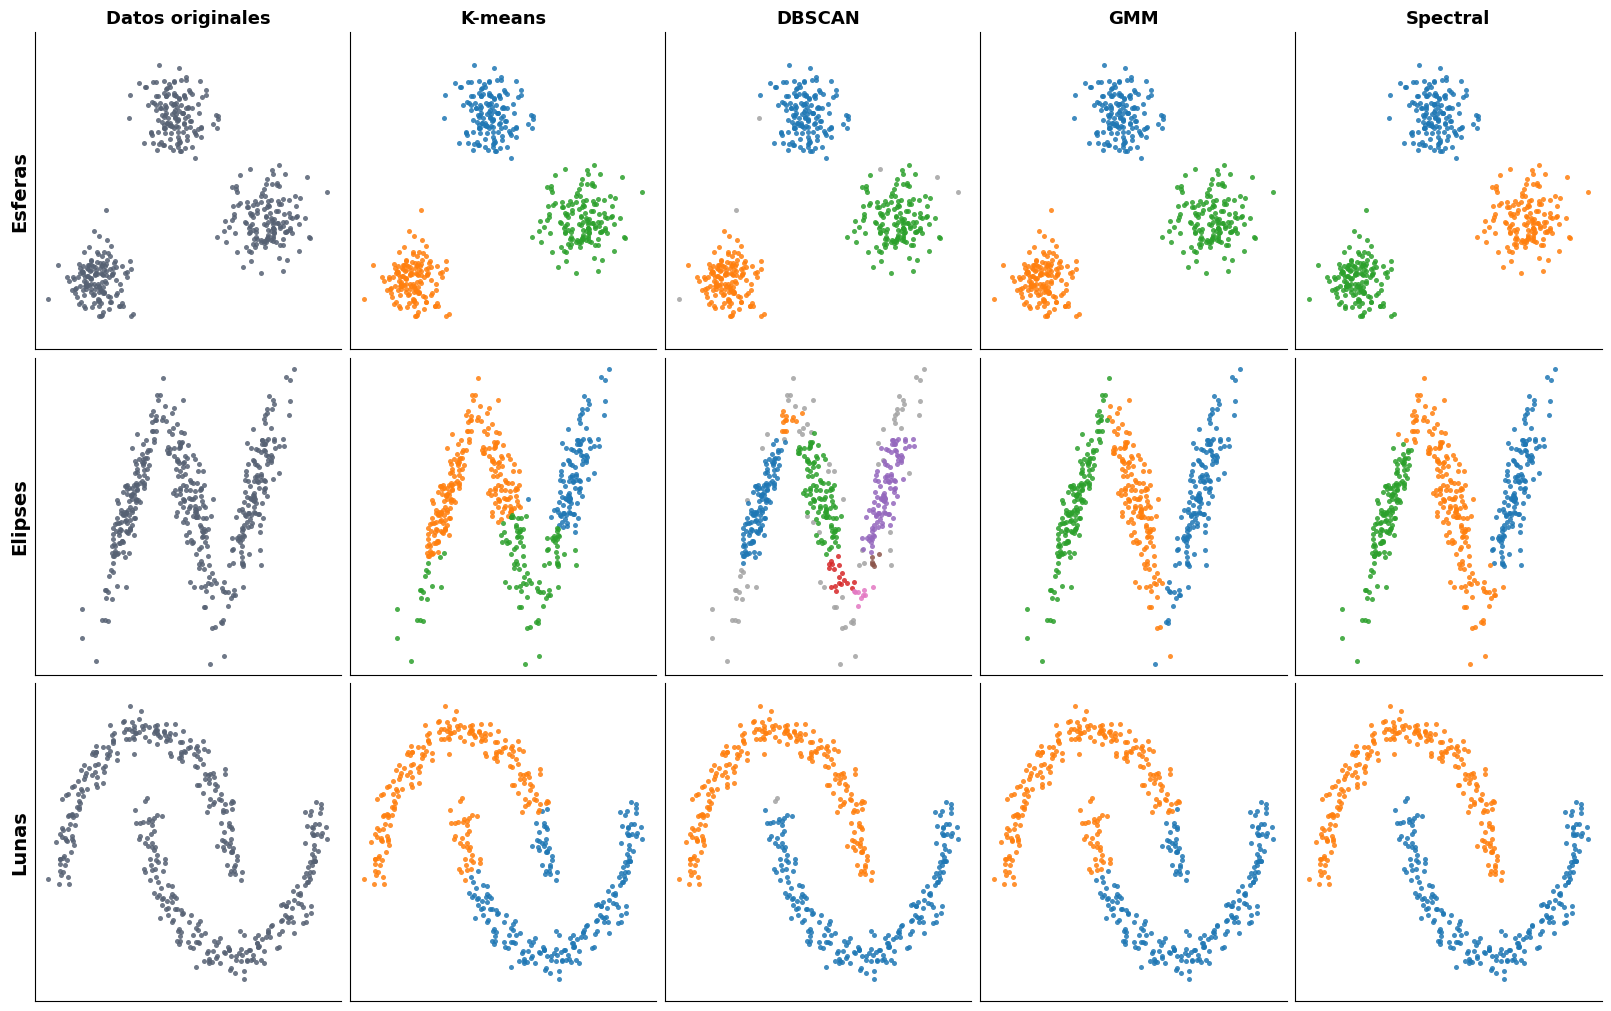

In [ ]:
colores = plt.get_cmap("tab10").colors
algoritmos = ["K-means", "DBSCAN", "GMM", "Spectral"]

def dibujar_clusters(ax, X, etiquetas):
    etiquetas = np.asarray(etiquetas)
    for grupo in np.unique(etiquetas):
        mask = etiquetas == grupo
        color = "#A3A3A3" if grupo == -1 else colores[int(grupo) % len(colores)]
        ax.scatter(X[mask, 0], X[mask, 1], s=13, color=color, alpha=0.85, linewidths=0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal", adjustable="datalim")

fig, axes = plt.subplots(3, 5, figsize=(16, 10), constrained_layout=True)
for fila, (nombre, caso) in enumerate(casos.items()):
    X = caso["X"]
    ax = axes[fila, 0]
    ax.scatter(X[:, 0], X[:, 1], s=13, color="#566173", alpha=0.85, linewidths=0)
    ax.set(xticks=[], yticks=[])
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_ylabel(nombre, fontsize=14, fontweight="bold")
    for columna, algoritmo in enumerate(algoritmos, start=1):
        dibujar_clusters(axes[fila, columna], X, resultados[nombre][algoritmo])

for ax, titulo in zip(axes[0], ["Datos originales"] + algoritmos):
    ax.set_title(titulo, fontsize=13, fontweight="bold")

plt.savefig("comparacion_clustering.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. ¿Cuántos grupos encontró cada algoritmo?

Aunque en esta actividad sabemos cómo se generaron los datos, en **aprendizaje no supervisado** el algoritmo no recibe esas etiquetas. Esta tabla solo resume las agrupaciones calculadas; **más grupos no implica un mejor resultado**.

In [ ]:
resumen = []
for caso, modelos in resultados.items():
    for algoritmo, etiquetas in modelos.items():
        etiquetas = np.asarray(etiquetas)
        grupos = set(etiquetas) - {-1}
        resumen.append({
            "Caso": caso,
            "Algoritmo": algoritmo,
            "Clústeres encontrados": len(grupos),
            "Puntos de ruido": int(np.sum(etiquetas == -1)),
        })

pd.DataFrame(resumen)

,Caso,Algoritmo,Clústeres encontrados,Puntos de ruido
0,Esferas,K-means,3,0
1,Esferas,DBSCAN,3,6
2,Esferas,GMM,3,0
3,Esferas,Spectral,3,0
4,Elipses,K-means,3,0
5,Elipses,DBSCAN,7,77
6,Elipses,GMM,3,0
7,Elipses,Spectral,3,0
8,Lunas,K-means,2,0
9,Lunas,DBSCAN,2,2


## 7. Una ventaja particular de GMM: probabilidades de pertenencia

A diferencia de la etiqueta final de K-means, un GMM puede estimar la **probabilidad de pertenencia** de cada punto a cada componente. En el ejemplo elíptico, colorearemos los puntos según su **máxima probabilidad de pertenencia**. Un valor próximo a 1 significa mayor confianza relativa del modelo; los valores menores indican asignaciones más ambiguas.

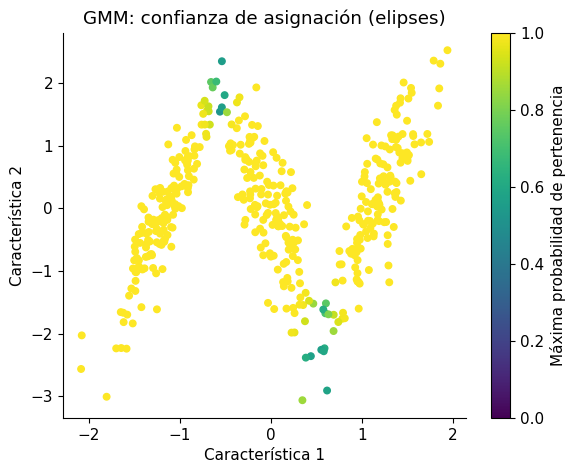

In [ ]:
X = casos["Elipses"]["X"]
gmm = GaussianMixture(n_components=3, covariance_type="full", n_init=5, random_state=SEED)
gmm.fit(X)
confianza = gmm.predict_proba(X).max(axis=1)

fig, ax = plt.subplots(figsize=(6.5, 5))
scatter = ax.scatter(X[:, 0], X[:, 1], c=confianza, cmap="viridis", vmin=0, vmax=1, s=22)
fig.colorbar(scatter, ax=ax, label="Máxima probabilidad de pertenencia")
ax.set(title="GMM: confianza de asignación (elipses)", xlabel="Característica 1", ylabel="Característica 2")
plt.show()

## 8. Actividad para experimentar

Regresa a la **sección 3**, modifica los parámetros de `casos` y vuelve a ejecutar las secciones **4 a 7**.

- **DBSCAN:** cambia `eps` en las lunas de `0.23` a `0.12` o `0.35`. ¿Aparecen más puntos de ruido? ¿Se fusionan los grupos?
- **Spectral Clustering:** cambia `gamma` para alterar cuánto decae la similitud entre puntos separados.
- **K-means y GMM:** cambia `k`. ¿Qué ocurre si impones un número incorrecto de grupos?
- **Datos:** aumenta `noise` en `make_moons` de `0.065` a `0.15` y ejecuta de nuevo.

### Ideas principales

**Grupos esféricos:** los cuatro métodos pueden encontrar una separación útil.  
**Grupos elípticos:** GMM puede aprovechar sus matrices de covarianza para modelar formas alargadas y orientadas; K-means se basa en distancias a centroides.  
**Lunas entrelazadas:** DBSCAN y Spectral Clustering pueden identificar formas no convexas que K-means y GMM no representan bien con sus supuestos usuales.

**Conclusión:** el resultado depende tanto de los datos y su escala como de la definición de clúster que utiliza cada método.

### Declaración de uso de IA generativa

Este notebook fue elaborado con apoyo de ChatGPT 6 High (OpenAI) para estructurar el contenido a partir de las diapositivas de la sesión y redactar el texto explicativo. El diseño pedagógico, la selección de temas y la revisión final son responsabilidad del titular del curso.